# 01 — Data Quality and Loan-Vintage Analysis

**Purpose:** create the full near-complete-cohort modeling population, retain a reproducible 100,000-row benchmark sample, and measure resolved-loan outcomes by origination year.

This notebook reads only the columns required for this project instead of loading the entire 151-column source file. The annual summary is calculated from **all eligible resolved loans**. The full eligible population and benchmark sample are saved separately.

> **Outcome caveat:** `default_rate` here means the share marked as default/charged-off among loans whose status is resolved in this dataset. It is not automatically the eventual default rate of every loan originated in that year. Unresolved loans are excluded, which can create maturity and selection bias, especially for newer vintages.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "accepted_2007_to_2018Q4.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_SIZE = 100_000
RANDOM_STATE = 42

if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {RAW_PATH.resolve()}. Place accepted_2007_to_2018Q4.csv "
        "inside data/raw/ and run this notebook from the notebooks/ directory."
    )

## 1. Define the outcome and the fields used

Positive class (`default = 1`): `Charged Off`, `Default`, and the charged-off credit-policy status.

Negative class (`default = 0`): `Fully Paid` and the fully-paid credit-policy status.

Statuses such as `Current`, `In Grace Period`, `Late`, and `Issued` are excluded because their outcomes are not resolved under this binary definition. They are not silently relabelled as non-defaults.

The full eligible population is retained; the separate benchmark sample is not used as a substitute for the full data in final analysis.

In [2]:
POSITIVE_STATUSES = {
    "Charged Off",
    "Default",
    "Does not meet the credit policy. Status:Charged Off",
}
NEGATIVE_STATUSES = {
    "Fully Paid",
    "Does not meet the credit policy. Status:Fully Paid",
}
VALID_STATUSES = POSITIVE_STATUSES | NEGATIVE_STATUSES

PREDICTOR_COLUMNS = [
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_length", "home_ownership", "annual_inc", "verification_status",
    "purpose", "dti", "delinq_2yrs", "fico_range_low", "fico_range_high",
    "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util",
    "total_acc", "application_type", "mort_acc", "pub_rec_bankruptcies",
]

RAW_COLUMNS = set(PREDICTOR_COLUMNS + [
    "issue_d",
    "loan_status",
    "last_pymnt_d",
    "last_credit_pull_d"
])
raw = pd.read_csv(
    RAW_PATH,
    usecols=lambda column: column in RAW_COLUMNS,
    low_memory=False,
)

# Stable row key from the source-file row order. This is used only to reproduce
# the 100,000-row benchmark from the full population; it is never a predictor.
raw["_source_row_id"] = np.arange(len(raw), dtype=np.int64)

required = {"issue_d", "loan_status"}
missing_required = required - set(raw.columns)
if missing_required:
    raise ValueError(f"Required source columns missing: {sorted(missing_required)}")

missing_predictors = sorted(set(PREDICTOR_COLUMNS) - set(raw.columns))
print("Raw rows read:", f"{len(raw):,}")
print("Columns loaded:", len(raw.columns))
print("Optional predictor columns not found:", missing_predictors)
print("Raw status counts (top 20):")
display(raw["loan_status"].value_counts(dropna=False).head(20).to_frame("rows"))

Raw rows read: 2,260,701
Columns loaded: 29
Optional predictor columns not found: []
Raw status counts (top 20):


,rows
loan_status,
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


In [3]:
date_columns = [
    "issue_d",
    "last_pymnt_d",
    "last_credit_pull_d"
]

for col in date_columns:
    if col not in raw.columns:
        print(f"\n{col}: Column not found")
        continue

    dates = pd.to_datetime(
        raw[col],
        format="%b-%Y",
        errors="coerce"
    )

    print(f"\n{col}")
    print("Earliest:", dates.min())
    print("Latest:", dates.max())
    print("Missing:", dates.isna().sum())


issue_d
Earliest: 2007-06-01 00:00:00
Latest: 2018-12-01 00:00:00
Missing: 33

last_pymnt_d
Earliest: 2007-12-01 00:00:00
Latest: 2019-03-01 00:00:00
Missing: 2460

last_credit_pull_d
Earliest: 2007-05-01 00:00:00
Latest: 2019-04-01 00:00:00
Missing: 105


In [4]:
# LendingClub issue_d values are commonly formatted like "Dec-2015".
raw["issue_date"] = pd.to_datetime(raw["issue_d"], format="%b-%Y", errors="coerce")
invalid_issue_date = int(raw["issue_date"].isna().sum())
print("Rows with unparsed issue dates:", f"{invalid_issue_date:,}")

resolved = raw.loc[
    raw["loan_status"].isin(VALID_STATUSES) & raw["issue_date"].notna()
].copy()
resolved["default"] = resolved["loan_status"].isin(POSITIVE_STATUSES).astype("int8")
resolved["issue_year"] = resolved["issue_date"].dt.year.astype("int16")
resolved["issue_quarter"] = resolved["issue_date"].dt.quarter.astype("int8")

print("Resolved rows with valid issue dates:", f"{len(resolved):,}")
print("Resolved-only default rate:", f"{resolved['default'].mean():.2%}")
print("Resolved target counts:")
display(resolved["default"].value_counts().rename(index={0: "Fully paid", 1: "Default/charged off"}).to_frame("rows"))

Rows with unparsed issue dates: 33
Resolved rows with valid issue dates: 1,348,099
Resolved-only default rate: 19.98%
Resolved target counts:


,rows
default,
Fully paid,1078739
Default/charged off,269360


In [5]:
raw["issue_year"] = raw["issue_date"].dt.year

raw_with_dates = raw.loc[
    raw["issue_year"].notna()
].copy()

status_by_origination_year = pd.crosstab(
    raw_with_dates["issue_year"],
    raw_with_dates["loan_status"]
)

display(status_by_origination_year)

loan_status,Charged Off,Current,Default,Does not meet the credit policy. Status:Charged Off,Does not meet the credit policy. Status:Fully Paid,Fully Paid,In Grace Period,Late (16-30 days),Late (31-120 days)
issue_year,,,,,,,,,
2007.0,45,0,0,113,239,206,0,0,0
2008.0,247,0,0,249,582,1315,0,0,0
2009.0,594,0,0,129,436,4122,0,0,0
2010.0,1487,0,0,270,731,10049,0,0,0
2011.0,3297,0,0,0,0,18424,0,0,0
2012.0,8644,0,0,0,0,44723,0,0,0
2013.0,21024,6,0,0,0,113780,1,0,3
2014.0,41161,11919,1,0,0,181941,200,73,334
2015.0,75803,43299,1,0,0,299742,612,279,1359


## 2. Analyze loan vintages before sampling

This summary uses all resolved rows available in the source file. Read it as a description of **resolved records**, not an unbiased lifetime default curve for all originated loans.

In [6]:
vintage_summary = (
    resolved.groupby("issue_year", as_index=False)
    .agg(
        resolved_loan_count=("default", "size"),
        default_count=("default", "sum"),
        observed_default_rate=("default", "mean"),
    )
    .sort_values("issue_year")
)
status_by_vintage = pd.crosstab(resolved["issue_year"], resolved["loan_status"])
status_by_vintage.index.name = "issue_year"

vintage_summary.to_csv(OUTPUT_DIR / "vintage_summary_resolved_only.csv", index=False)
status_by_vintage.to_csv(OUTPUT_DIR / "resolved_status_counts_by_year.csv")

display(vintage_summary)

,issue_year,resolved_loan_count,default_count,observed_default_rate
0,2007,603,158,0.262023
1,2008,2393,496,0.207271
2,2009,5281,723,0.136906
3,2010,12537,1757,0.140145
4,2011,21721,3297,0.151789
5,2012,53367,8644,0.161973
6,2013,134804,21024,0.155960
7,2014,223103,41162,0.184498
8,2015,375546,75804,0.201850
9,2016,293105,68252,0.232859


In [7]:
# Summarize outcome maturity and observed defaults by origination-year / loan-term cohort.
vintage_term_summary = (
    raw_with_dates.assign(
        is_resolved=raw_with_dates["loan_status"].isin(VALID_STATUSES),
        is_default=raw_with_dates["loan_status"].isin(POSITIVE_STATUSES),
    )
    .groupby(["issue_year", "term"], dropna=False)
    .agg(
        total_loans=("loan_status", "size"),
        resolved_loans=("is_resolved", "sum"),
        default_loans=("is_default", "sum"),
    )
    .reset_index()
)

vintage_term_summary["unresolved_loans"] = (
    vintage_term_summary["total_loans"] - vintage_term_summary["resolved_loans"]
)
vintage_term_summary["resolved_share"] = (
    vintage_term_summary["resolved_loans"] / vintage_term_summary["total_loans"]
)
vintage_term_summary["default_rate_among_resolved"] = (
    vintage_term_summary["default_loans"]
    / vintage_term_summary["resolved_loans"].replace(0, np.nan)
)

vintage_term_summary.to_csv(
    OUTPUT_DIR / "vintage_term_maturity_summary.csv",
    index=False,
)
display(vintage_term_summary.round(4))

,issue_year,term,total_loans,resolved_loans,default_loans,unresolved_loans,resolved_share,default_rate_among_resolved
0,2007.0,36 months,603,603,158,0,1.0000,0.2620
1,2008.0,36 months,2393,2393,496,0,1.0000,0.2073
2,2009.0,36 months,5281,5281,723,0,1.0000,0.1369
3,2010.0,36 months,9156,9156,1000,0,1.0000,0.1092
4,2010.0,60 months,3381,3381,757,0,1.0000,0.2239
5,2011.0,36 months,14101,14101,1499,0,1.0000,0.1063
6,2011.0,60 months,7620,7620,1798,0,1.0000,0.2360
7,2012.0,36 months,43470,43470,5903,0,1.0000,0.1358
8,2012.0,60 months,9897,9897,2741,0,1.0000,0.2770
9,2013.0,36 months,100422,100422,12378,0,1.0000,0.1233


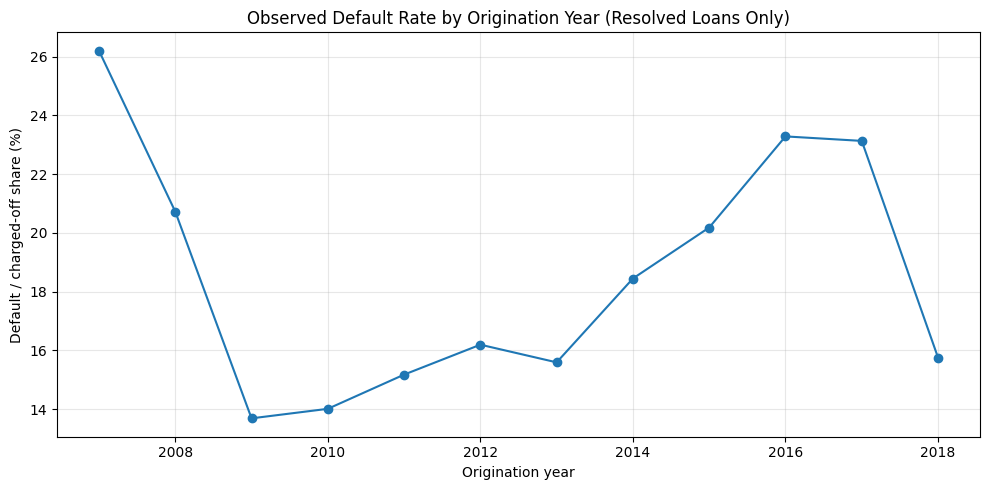

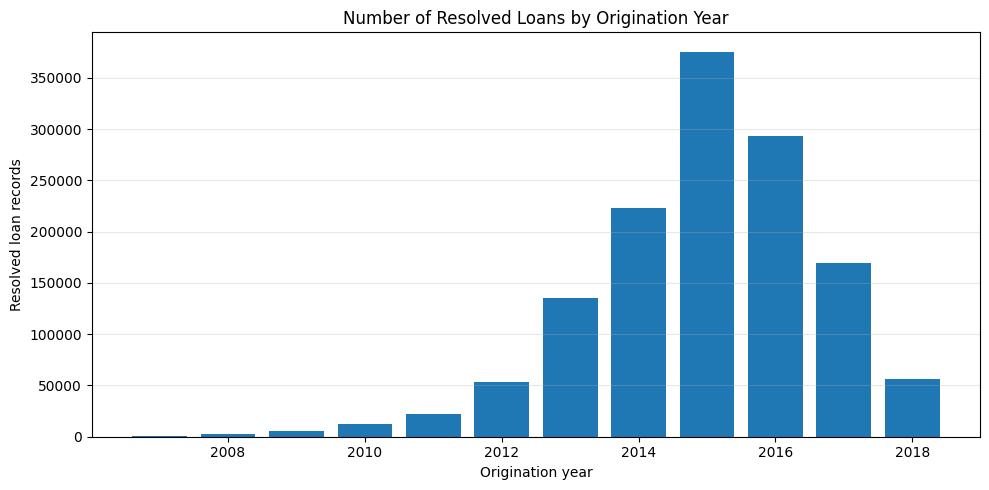

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    vintage_summary["issue_year"],
    vintage_summary["observed_default_rate"] * 100,
    marker="o",
)
ax.set_title("Observed Default Rate by Origination Year (Resolved Loans Only)")
ax.set_xlabel("Origination year")
ax.set_ylabel("Default / charged-off share (%)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(vintage_summary["issue_year"], vintage_summary["resolved_loan_count"])
ax.set_title("Number of Resolved Loans by Origination Year")
ax.set_xlabel("Origination year")
ax.set_ylabel("Resolved loan records")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Create the full eligible population and a reproducible benchmark sample

For this project, a loan-term/origination-year cohort is eligible when at least **99.5% of its records have a resolved status** in the downloaded file. This is an explicit operational maturity rule based on the observed data, not a verified official snapshot date or a fixed-horizon default label.

Only resolved records from eligible cohorts are retained for this binary-label modeling experiment. The notebook now saves **all eligible resolved records** for the main analysis and a separate 100,000-row sample for a reproducible benchmark. The sample is drawn within the target classes so it approximately preserves the eligible population's default prevalence.

Unresolved records are not labelled as non-defaults. The small remaining unresolved fraction in an eligible cohort, unequal follow-up and resolved-only selection remain limitations.

In [9]:
# Select near-complete origination-year / loan-term cohorts.
MIN_RESOLVED_SHARE = 0.995

eligible_cohorts = vintage_term_summary.loc[
    vintage_term_summary["resolved_share"] >= MIN_RESOLVED_SHARE,
    [
        "issue_year", "term", "total_loans", "resolved_loans",
        "unresolved_loans", "resolved_share", "default_rate_among_resolved",
    ],
].copy()

if eligible_cohorts.empty:
    raise ValueError(
        "No origination-year / term cohorts meet the resolved-share threshold. "
        "Review MIN_RESOLVED_SHARE and the status summary."
    )

# Use consistent integer year values for the cohort join.
eligible_cohorts["issue_year"] = eligible_cohorts["issue_year"].astype(int)
resolved_for_modeling = resolved.copy()
resolved_for_modeling["issue_year"] = resolved_for_modeling["issue_year"].astype(int)

mature_resolved = resolved_for_modeling.merge(
    eligible_cohorts[["issue_year", "term"]],
    on=["issue_year", "term"],
    how="inner",
    validate="many_to_one",
)

if mature_resolved.empty:
    raise ValueError("The maturity filter produced no resolved loan records.")

available_predictors = [
    column for column in PREDICTOR_COLUMNS
    if column in mature_resolved.columns
]
metadata_columns = [
    "_source_row_id", "issue_date", "issue_year", "issue_quarter"
]
model_columns = metadata_columns + available_predictors + ["default"]
model_data = mature_resolved[model_columns].copy()

# The source row key must be unique so the benchmark sample can be recreated
# exactly after feature engineering.
if model_data["_source_row_id"].isna().any() or model_data["_source_row_id"].duplicated().any():
    raise ValueError("_source_row_id is missing or duplicated in the eligible population.")

model_data = model_data.sort_values("_source_row_id").reset_index(drop=True)

# Save the complete eligible population for the main analysis.
full_path = PROCESSED_DIR / "modeling_full.csv"
model_data.to_csv(full_path, index=False)

# Preserve the earlier 100,000-row experiment as a benchmark. Sampling within
# the two target classes preserves the overall default prevalence approximately.
sample_n = min(SAMPLE_SIZE, len(model_data))
if sample_n < len(model_data):
    default_rows = model_data.loc[model_data["default"] == 1]
    nondefault_rows = model_data.loc[model_data["default"] == 0]

    default_share = float(model_data["default"].mean())
    n_default = min(len(default_rows), int(round(sample_n * default_share)))
    n_nondefault = sample_n - n_default
    if n_nondefault > len(nondefault_rows):
        n_nondefault = len(nondefault_rows)
        n_default = sample_n - n_nondefault

    default_sample = default_rows.sample(n=n_default, random_state=RANDOM_STATE)
    nondefault_sample = nondefault_rows.sample(n=n_nondefault, random_state=RANDOM_STATE)
    model_sample = pd.concat([default_sample, nondefault_sample], axis=0)
else:
    model_sample = model_data.copy()

model_sample = (
    model_sample.sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

sample_path = PROCESSED_DIR / "modeling_sample.csv"
model_sample.to_csv(sample_path, index=False)

eligible_cohorts.to_csv(
    OUTPUT_DIR / "eligible_mature_cohorts.csv",
    index=False,
)

# Save full-population cohort profile for the modeling handoff.
full_term_year_profile = (
    model_data.groupby(["term", "issue_year"], dropna=False)
    .agg(
        loans=("default", "size"),
        defaults=("default", "sum"),
        default_rate=("default", "mean"),
    )
    .reset_index()
    .sort_values(["term", "issue_year"])
)
full_term_year_profile["non_defaults"] = (
    full_term_year_profile["loans"] - full_term_year_profile["defaults"]
)
full_term_year_profile.to_csv(
    OUTPUT_DIR / "eligible_population_term_year_profile.csv",
    index=False,
)

print(f"Resolved-share threshold: {MIN_RESOLVED_SHARE:.1%}")
print("Eligible origination-year / term cohorts:")
display(eligible_cohorts.round(4))

print("Full eligible resolved population:", f"{len(model_data):,}")
print("Full population saved:", full_path)
print("Full population default rate:", f"{model_data['default'].mean():.2%}")
print("\nFull population by term and origination year:")
display(full_term_year_profile.round(4))

print("\nBenchmark sample saved:", sample_path)
print("Benchmark sample shape:", model_sample.shape)
print("Benchmark sample class distribution:")
display(
    model_sample["default"]
    .value_counts()
    .rename(index={0: "Fully paid", 1: "Default / charged off"})
    .to_frame("rows")
)
print("Benchmark sample default share:", f"{model_sample['default'].mean():.2%}")


Resolved-share threshold: 99.5%
Eligible origination-year / term cohorts:


,issue_year,term,total_loans,resolved_loans,unresolved_loans,resolved_share,default_rate_among_resolved
0,2007,36 months,603,603,0,1.0000,0.2620
1,2008,36 months,2393,2393,0,1.0000,0.2073
2,2009,36 months,5281,5281,0,1.0000,0.1369
3,2010,36 months,9156,9156,0,1.0000,0.1092
4,2010,60 months,3381,3381,0,1.0000,0.2239
5,2011,36 months,14101,14101,0,1.0000,0.1063
6,2011,60 months,7620,7620,0,1.0000,0.2360
7,2012,36 months,43470,43470,0,1.0000,0.1358
8,2012,60 months,9897,9897,0,1.0000,0.2770
9,2013,36 months,100422,100422,0,1.0000,0.1233


Full eligible resolved population: 676,302
Full population saved: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\processed\modeling_full.csv
Full population default rate: 14.87%

Full population by term and origination year:


,term,issue_year,loans,defaults,default_rate,non_defaults
0,36 months,2007,603,158,0.2620,445
1,36 months,2008,2393,496,0.2073,1897
2,36 months,2009,5281,723,0.1369,4558
3,36 months,2010,9156,1000,0.1092,8156
4,36 months,2011,14101,1499,0.1063,12602
5,36 months,2012,43470,5903,0.1358,37567
6,36 months,2013,100422,12378,0.1233,88044
7,36 months,2014,162570,22315,0.1373,140255
8,36 months,2015,283026,42132,0.1489,240894
9,60 months,2010,3381,757,0.2239,2624



Benchmark sample saved: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\processed\modeling_sample.csv
Benchmark sample shape: (100000, 29)
Benchmark sample class distribution:


,rows
default,
Fully paid,85133
Default / charged off,14867


Benchmark sample default share: 14.87%
